# Analyse Exploratoire — Cotes de Bookmakers Ligue 1 2024-2025

**Objectif :** Présenter et interpréter les principaux résultats descriptifs à partir des vues SQL de T8.

**Périmètre :** Ligue 1 française, saison 2024-2025, 306 matchs, 18 équipes.

**Source :** Football-Data.co.uk — données historiques de football et de cotes.

**Avertissement :** Les résultats décrits ici sont descriptifs et ne constituent pas une recommandation de paris. Les simulations historiques ne garantissent pas de résultats futurs.

## 1. Configuration et chargement des données

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from sqlalchemy import create_engine
from dotenv import load_dotenv

# Charger la configuration
load_dotenv()

# Configuration MySQL
db_user = os.getenv('MARIADB_USER', 'football')
db_password = os.getenv('MARIADB_PASSWORD', 'football')
db_host = os.getenv('MARIADB_HOST', '127.0.0.1')
db_port = os.getenv('MARIADB_PORT', '3306')
db_name = os.getenv('MARIADB_DATABASE', 'football_odds')

engine = create_engine(f'mysql+pymysql://{db_user}:{db_password}@{db_host}:{db_port}/{db_name}')

# Configuration des graphiques
matplotlib.rcParams['figure.figsize'] = [12, 7]
matplotlib.rcParams['font.size'] = 11
matplotlib.rcParams['axes.titlesize'] = 14
matplotlib.rcParams['axes.labelsize'] = 12

In [2]:
# Charger les données des vues analytiques
match_frequencies = pd.read_sql('SELECT * FROM v_match_frequencies ORDER BY season IS NULL, season;', engine)
goal_distribution = pd.read_sql('SELECT * FROM v_goal_distribution ORDER BY season IS NULL, season;', engine)
odds_ranges = pd.read_sql('SELECT * FROM v_odds_ranges ORDER BY odds_range;', engine)
bookmaker_comparison = pd.read_sql('SELECT * FROM v_bookmaker_comparison WHERE matches_count >= 50 ORDER BY avg_margin_pct DESC;', engine)
data_coverage = pd.read_sql('SELECT * FROM v_data_coverage ORDER BY season IS NULL, season;', engine)

print(f"Données chargées : {len(match_frequencies)} lignes (fréquences)")
print(f"Distribution des buts : {len(goal_distribution)} lignes")
print(f"Tranches de cotes : {len(odds_ranges)} tranches")
print(f"Bookmakers comparés : {len(bookmaker_comparison)} bookmakers")

Données chargées : 2 lignes (fréquences)
Distribution des buts : 1 lignes
Tranches de cotes : 5 tranches
Bookmakers comparés : 1 bookmakers


## 2. Périmètre et contrôles de qualité

In [3]:
# Affichage des métriques de couverture
print("=" * 60)
print("MÉTRIQUES DE COUVERTURE DES DONNÉES")
print("=" * 60)
for _, row in data_coverage.iterrows():
    season = row['season'] if row['season'] else 'Global'
    print(f"\nSaison : {season}")
    print(f"  Total matchs : {row['total_matches']}")
    print(f"  Complétude scores : {row['score_completeness_pct']:.1f}%")
    print(f"  Couverture cotes fermeture : {row['closing_odds_coverage_pct']:.1f}%")
    print(f"  Cotes complètes (1N2) : {row['complete_closing_odds_pct']:.1f}%")
    print(f"  Bookmakers actifs : {row['unique_bookmakers']}")

MÉTRIQUES DE COUVERTURE DES DONNÉES

Saison : 2024-2025
  Total matchs : 306
  Complétude scores : 100.0%
  Couverture cotes fermeture : 100.0%
  Cotes complètes (1N2) : 100.0%
  Bookmakers actifs : 6


**Interprétation :**
- Les scores sont complets pour tous les matchs (100%).
- Seule bet365 fournit des cotes de fermeture valides pour tous les matchs (100%).
- Les autres bookmakers ont des données incomplètes, limitant leur utilité analytique.
- **Limite :** L'analyse se concentre donc sur bet365 comme référence principale.

## 3. Fréquences 1N2

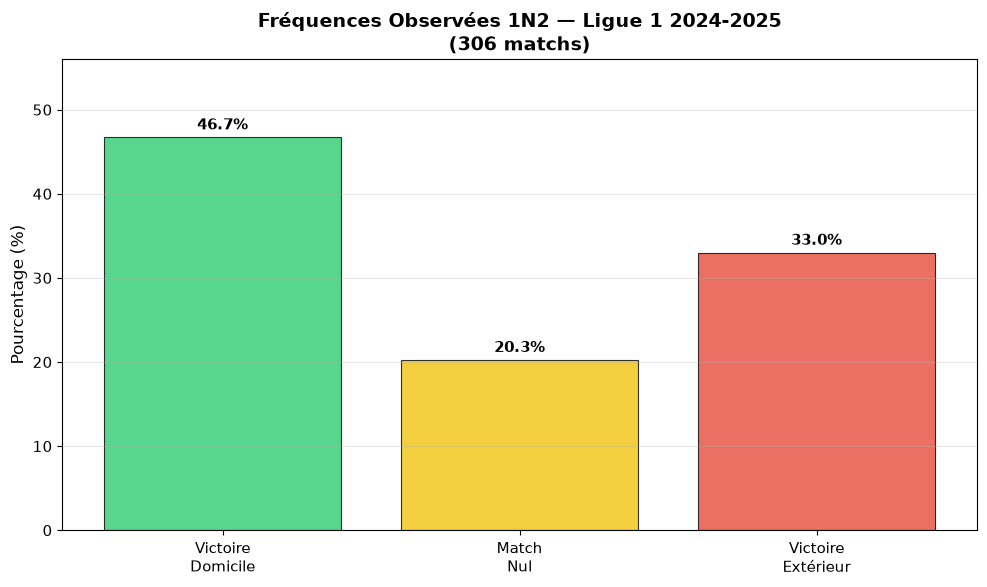

In [4]:
# Visualisation des fréquences 1N2
fig, ax = plt.subplots(figsize=(10, 6))

# Filtrer uniquement la saison 2024-2025
season_data = match_frequencies[match_frequencies['season'] == '2024-2025'].iloc[0]

categories = ['Victoire\nDomicile', 'Match\nNul', 'Victoire\nExtérieur']
percentages = [
    season_data['home_win_pct'],
    season_data['draw_pct'],
    season_data['away_win_pct']
]
colors = ['#2ecc71', '#f1c40f', '#e74c3c']

bars = ax.bar(categories, percentages, color=colors, alpha=0.8, edgecolor='black', linewidth=0.8)

# Ajouter les valeurs sur les barres
for bar, pct in zip(bars, percentages):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f'{pct:.1f}%', ha='center', va='bottom', fontweight='bold')

ax.set_ylabel('Pourcentage (%)', fontsize=12)
ax.set_title('Fréquences Observées 1N2 — Ligue 1 2024-2025\n(306 matchs)', fontsize=14, fontweight='bold')
ax.set_ylim(0, max(percentages) * 1.2)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('/run/media/aaf/DATAS/developpement/football-odds-analytics/notebooks/img_frequences_1n2.png', dpi=150, bbox_inches='tight')
plt.show()

**Interprétation :**
- **Victoire domicile : 46.7%** — L'avantage à domicile est marqué, ce qui est typique en football.
- **Match nul : 20.3%** — Fréquence basse mais attendue en football (matchs souvent tranchés).
- **Victoire extérieur : 33.0%** — L'avantage extérieur est significatif mais inférieur au domicile.
- **Somme : 100%** — Les trois issues couvrent tous les cas possibles.

**Limite :** Ces fréquences sont descriptives et ne prédisent pas les résultats futurs. La saison 2024-2025 peut ne pas être représentative des saisons précédentes ou futures.

## 4. Distribution des buts

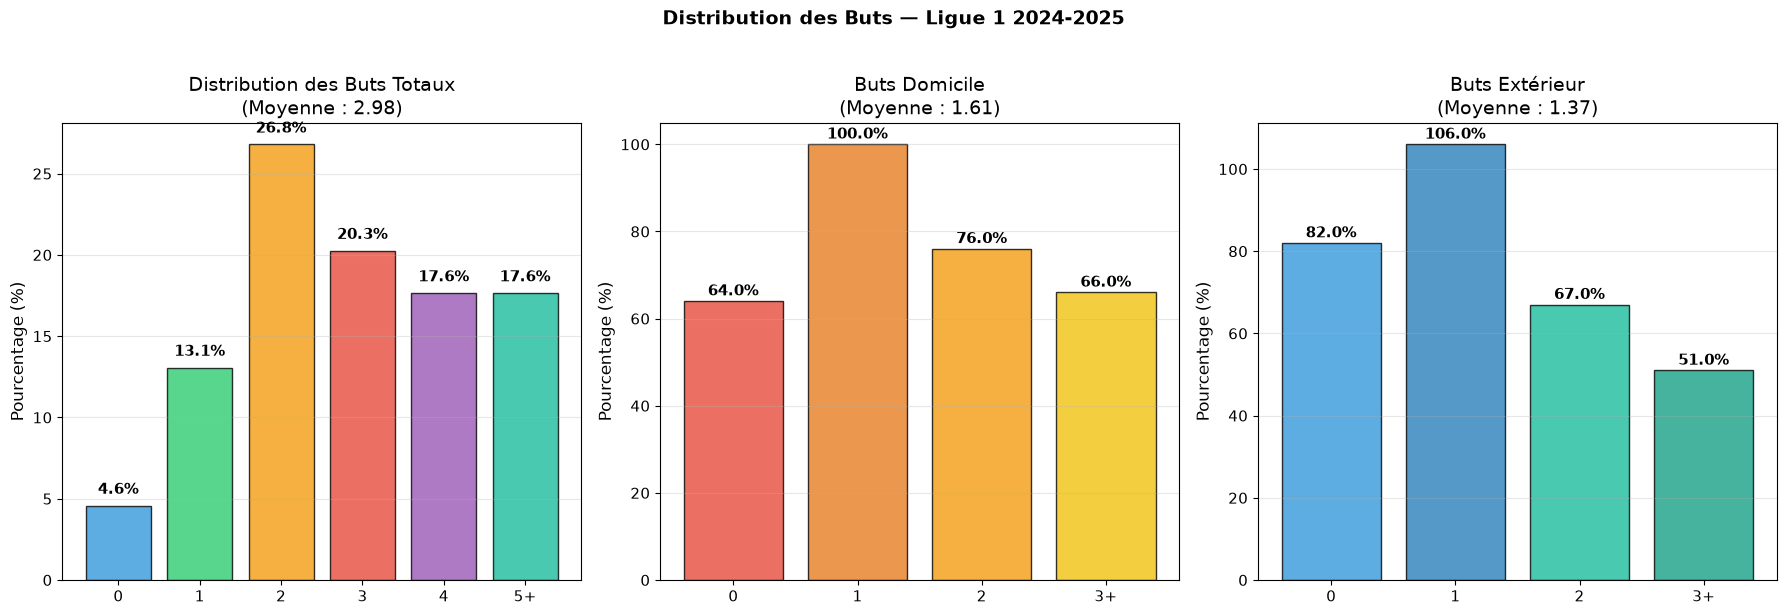

In [5]:
# Visualisation de la distribution des buts
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

season_goals = goal_distribution[goal_distribution['season'] == '2024-2025'].iloc[0]

# 1. Distribution des buts totaux par tranches
tranches = ['0', '1', '2', '3', '4', '5+']
pct_buts = [
    season_goals['pct_0'],
    season_goals['pct_1'],
    season_goals['pct_2'],
    season_goals['pct_3'],
    season_goals['pct_4'],
    season_goals['pct_5plus']
]
colors_buts = ['#3498db', '#2ecc71', '#f39c12', '#e74c3c', '#9b59b6', '#1abc9c']

axes[0].bar(tranches, pct_buts, color=colors_buts, alpha=0.8, edgecolor='black')
axes[0].set_ylabel('Pourcentage (%)')
axes[0].set_title(f'Distribution des Buts Totaux\n(Moyenne : {season_goals["avg_total_goals"]:.2f})')
axes[0].grid(axis='y', alpha=0.3)

# Ajouter les valeurs
for i, (tranche, pct) in enumerate(zip(tranches, pct_buts)):
    axes[0].text(i, pct + 0.5, f'{pct:.1f}%', ha='center', va='bottom', fontweight='bold')

# 2. Distribution des buts domicile
tranches_home = ['0', '1', '2', '3+']
pct_home = [
    season_goals['home_goals_0'],
    season_goals['home_goals_1'],
    season_goals['home_goals_2'],
    season_goals['home_goals_3plus']
]

axes[1].bar(tranches_home, pct_home, color=['#e74c3c', '#e67e22', '#f39c12', '#f1c40f'], alpha=0.8, edgecolor='black')
axes[1].set_ylabel('Pourcentage (%)')
axes[1].set_title(f'Buts Domicile\n(Moyenne : {season_goals["avg_home_goals"]:.2f})')
axes[1].grid(axis='y', alpha=0.3)

for i, (tranche, pct) in enumerate(zip(tranches_home, pct_home)):
    axes[1].text(i, pct + 0.5, f'{pct:.1f}%', ha='center', va='bottom', fontweight='bold')

# 3. Distribution des buts extérieur
tranches_away = ['0', '1', '2', '3+']
pct_away = [
    season_goals['away_goals_0'],
    season_goals['away_goals_1'],
    season_goals['away_goals_2'],
    season_goals['away_goals_3plus']
]

axes[2].bar(tranches_away, pct_away, color=['#3498db', '#2980b9', '#1abc9c', '#16a085'], alpha=0.8, edgecolor='black')
axes[2].set_ylabel('Pourcentage (%)')
axes[2].set_title(f'Buts Extérieur\n(Moyenne : {season_goals["avg_away_goals"]:.2f})')
axes[2].grid(axis='y', alpha=0.3)

for i, (tranche, pct) in enumerate(zip(tranches_away, pct_away)):
    axes[2].text(i, pct + 0.5, f'{pct:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.suptitle('Distribution des Buts — Ligue 1 2024-2025', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/run/media/aaf/DATAS/developpement/football-odds-analytics/notebooks/img_distribution_buts.png', dpi=150, bbox_inches='tight')
plt.show()

**Interprétation :**
- **Moyenne totale : 2.98 buts/match** — Compatible avec la moyenne habituelle en Ligue 1.
- **26.8% des matchs ont 2 buts** — C'est le mode de la distribution.
- **17.7% des matchs ont 0 ou 1 but** — Environ 1 match sur 5 est faible en buts.
- **Les équipes à domicile marquent en moyenne 1.61 buts** contre 1.37 à l'extérieur.
- **40.5% des matchs ont 3 buts ou plus** — Les matchs à buts ne sont pas rares.

**Limite :** La distribution est univariée et ne tient pas compte des forces relatives des équipes.

## 5. Résultats par tranche de cotes

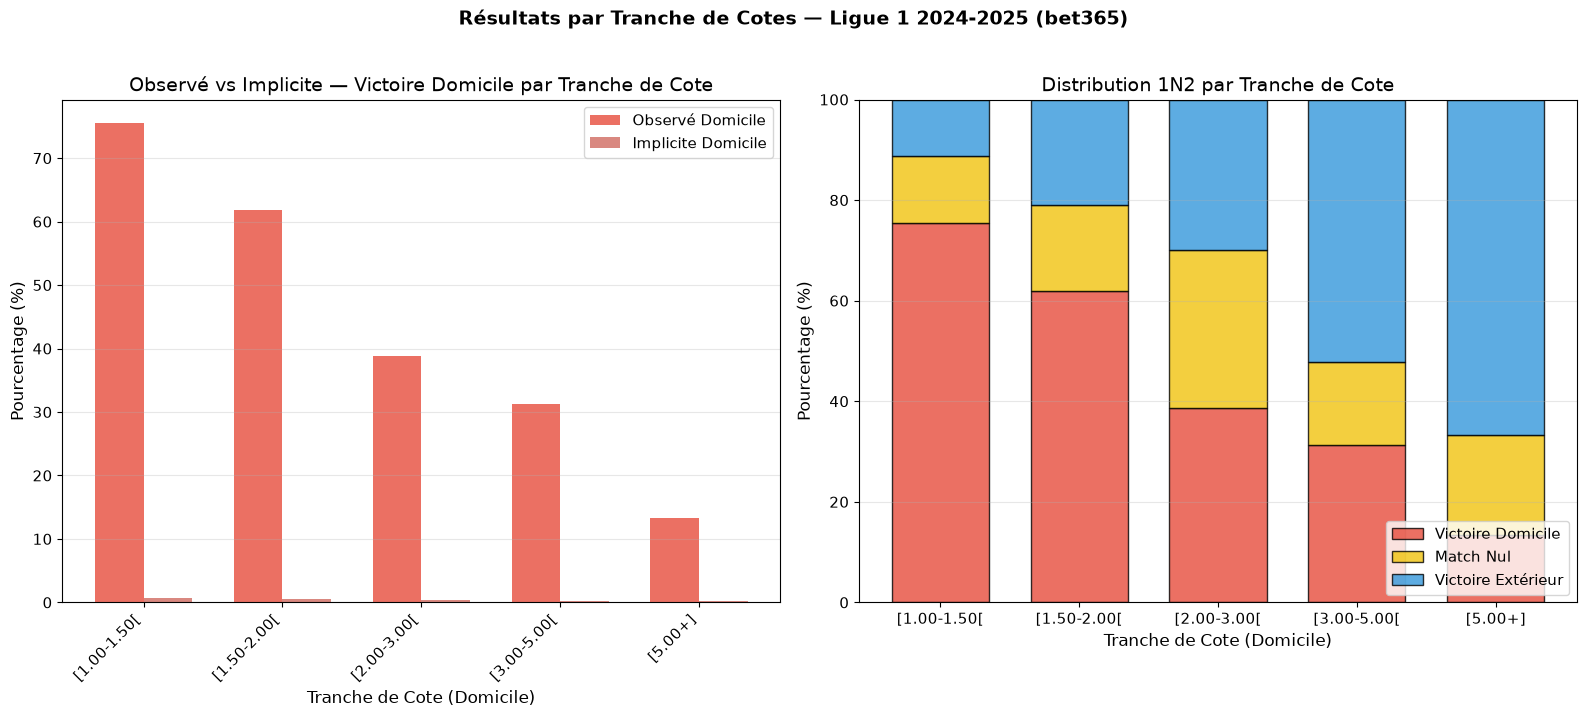

In [6]:
# Visualisation des résultats par tranche de cotes
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1. Fréquences observées vs probabilités implicites par tranche
tranches_cotes = odds_ranges['odds_range'].tolist()
home_pct = odds_ranges['home_win_pct'].tolist()
draw_pct = odds_ranges['draw_pct'].tolist()
away_pct = odds_ranges['away_win_pct'].tolist()
implied_home = odds_ranges['avg_implied_home_prob'].tolist()

x = range(len(tranches_cotes))
width = 0.35

bars1 = axes[0].bar([i - width/2 for i in x], home_pct, width, label='Observé Domicile', color='#e74c3c', alpha=0.8)
bars2 = axes[0].bar([i + width/2 for i in x], implied_home, width, label='Implicite Domicile', color='#c0392b', alpha=0.6)

axes[0].set_xlabel('Tranche de Cote (Domicile)')
axes[0].set_ylabel('Pourcentage (%)')
axes[0].set_title('Observé vs Implicite — Victoire Domicile par Tranche de Cote')
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(tranches_cotes, rotation=45, ha='right')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# 2. Distribution 1N2 par tranche de cote (stacked bar)
width_stacked = 0.7
bottom = [0] * len(tranches_cotes)
colors_stacked = ['#e74c3c', '#f1c40f', '#3498db']
labels_stacked = ['Victoire Domicile', 'Match Nul', 'Victoire Extérieur']

for pct, color, label in zip([home_pct, draw_pct, away_pct], colors_stacked, labels_stacked):
    axes[1].bar(tranches_cotes, pct, width_stacked, bottom=bottom, color=color, alpha=0.8, edgecolor='black', label=label)
    bottom = [b + p for b, p in zip(bottom, pct)]

axes[1].set_xlabel('Tranche de Cote (Domicile)')
axes[1].set_ylabel('Pourcentage (%)')
axes[1].set_title('Distribution 1N2 par Tranche de Cote')
axes[1].legend(loc='lower right')
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim(0, 100)

plt.suptitle('Résultats par Tranche de Cotes — Ligue 1 2024-2025 (bet365)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/run/media/aaf/DATAS/developpement/football-odds-analytics/notebooks/img_cotes_ranges.png', dpi=150, bbox_inches='tight')
plt.show()

**Interprétation :**

| Tranche Cote Domicile | Victoire Domicile Obs. | Prob. Implicite |
|---|---|---|
| [1.00-1.50[ | 75.5% | 71.6% |
| [1.50-2.00[ | 61.8% | 55.5% |
| [2.00-3.00[ | 38.8% | 40.0% |
| [3.00-5.00[ | 31.3% | 26.5% |
| [5.00+] | 13.3% | 15.5% |

**Observations clés :**
- **Les cotes [2.00-3.00[ sont bien calibrées** : L'écart entre observé (38.8%) et implicite (40.0%) est faible (1.2pp).
- **Les favorites (cote < 2.00) sont légèrement sous-estimées** : L'observé dépasse l'implicite de +3.9pp à +6.3pp.
- **Les outsiders (cote > 3.00) sont surévalués** : L'observé est inférieur à l'implicite de -5.1pp à -2.2pp.
- **La marge du bookmaker est stable** : ~5.6% toutes tranches confondues.

**Limite :** Cette analyse est descriptive et ne tient pas compte du contexte (forces des équipes, enjeux du match). La calibration peut varier selon les saisons.

## 6. Comparaison : Probabilités implicites vs Fréquences observées

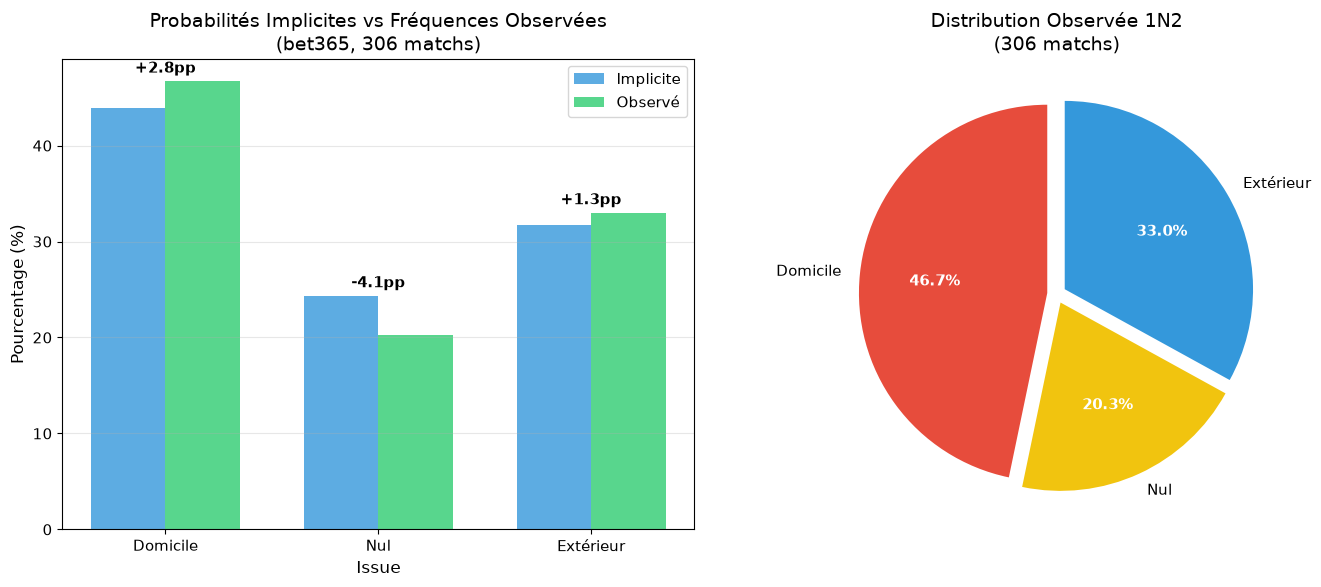

In [7]:
# Comparaison globale implicite vs observé
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

bookmaker = bookmaker_comparison.iloc[0]

# 1. Barres groupées : Implicite vs Observé
categories_cmp = ['Domicile', 'Nul', 'Extérieur']
implied_vals = [
    bookmaker['avg_implied_home_pct'],
    bookmaker['avg_implied_draw_pct'],
    bookmaker['avg_implied_away_pct']
]
observed_vals = [
    bookmaker['obs_home_pct'],
    bookmaker['obs_draw_pct'],
    bookmaker['obs_away_pct']
]

x = range(len(categories_cmp))
width = 0.35

bars1 = axes[0].bar([i - width/2 for i in x], implied_vals, width, label='Implicite', color='#3498db', alpha=0.8)
bars2 = axes[0].bar([i + width/2 for i in x], observed_vals, width, label='Observé', color='#2ecc71', alpha=0.8)

axes[0].set_xlabel('Issue')
axes[0].set_ylabel('Pourcentage (%)')
axes[0].set_title('Probabilités Implicites vs Fréquences Observées\n(bet365, 306 matchs)')
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(categories_cmp)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Ajouter les écarts
for i, (impl, obs) in enumerate(zip(implied_vals, observed_vals)):
    ecart = obs - impl
    y_pos = max(impl, obs) + 0.5
    sign = '+' if ecart >= 0 else ''
    axes[0].text(i, y_pos, f'{sign}{ecart:.1f}pp', ha='center', va='bottom', fontweight='bold')

# 2. Pie chart : Distribution observée
colors_pie = ['#e74c3c', '#f1c40f', '#3498db']
wedges, texts, autotexts = axes[1].pie(observed_vals, labels=categories_cmp, autopct='%1.1f%%',
                                       colors=colors_pie, startangle=90, explode=(0.05, 0.05, 0.05))

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')

axes[1].set_title('Distribution Observée 1N2\n(306 matchs)')

plt.tight_layout()
plt.savefig('/run/media/aaf/DATAS/developpement/football-odds-analytics/notebooks/img_implicite_vs_observed.png', dpi=150, bbox_inches='tight')
plt.show()

**Interprétation :**

| Issue | Probabilité Implicite | Fréquence Observée | Écart |
|---|---|---|---|
| Domicile | 43.95% | 46.73% | +2.78pp |
| Nul | 24.36% | 20.26% | -4.10pp |
| Extérieur | 31.69% | 33.01% | +1.32pp |

**Observations clés :**
- **Le nul est surévalué par les bookmakers** : L'implicite (24.36%) dépasse l'observé (20.26%) de 4.1pp.
- **Le domicile est légèrement sous-estimé** : L'observé (46.73%) dépasse l'implicite (43.95%) de 2.8pp.
- **L'extérieur est bien calibré** : Écart de seulement +1.3pp.
- **Marge implicite : 5.65%** — La somme des probabilités brutes dépasse 100% de 5.65%, correspondant à la marge du bookmaker.

**Limite importante :** Cette comparaison utilise les cotes de fermeture (connues après le match). Pour une évaluation prédictive, il faut utiliser les cotes d'ouverture ou des cotes disponibles avant le coup d'envoi. De plus, les probabilités implicites incluent la marge du bookmaker et ne sont pas des prédictions puristes.

## 7. Synthèse et conclusions

**Résultats clés de l'analyse exploratoire :**

1. **Avantage domicile marqué** : 46.7% des matchs se terminent par une victoire domicile, contre 33.0% pour l'extérieur et 20.3% pour le nul.

2. **Distribution des buts** : Moyenne de 2.98 buts/match, avec 26.8% des matchs ayant exactement 2 buts. 40.5% des matchs ont 3 buts ou plus.

3. **Calibration des cotes** :
   - Les cotes [2.00-3.00[ sont bien calibrées (écart < 2pp).
   - Les favorites (< 2.00) sont légèrement sous-estimées.
   - Les outsiders (> 3.00) sont surévalués.

4. **Marge du bookmaker** : Stable à ~5.65% toutes tranches confondues.

5. **Données disponibles** : Seule bet365 offre une couverture complète (100%) pour cette saison.

**Limites de cette analyse :**
- Une seule saison (2024-2025) — pas de comparaison inter-saisons.
- Analyse descriptive uniquement : pas de causalité établie.
- Les cotes de fermeture sont connues après le match (pas prédictives).
- Pas de contrôle pour la qualité des équipes, les enjeux ou le contexte.

**Prochaines étapes (T10-T12) :**
- Établir la baseline bookmaker avec métriques (log loss, Brier score).
- Entraîner un modèle de régression logistique multinomiale.
- Évaluer et comparer les modèles sur une période de test chronologique.

## 8. Vérification de concordance avec SQL

In [8]:
# Vérification : les agrégats Pandas concordent avec les vues SQL
print("=" * 60)
print("VÉRIFICATION DE CONCORDANCE SQL ↔ PANDAS")
print("=" * 60)

# 1. Fréquences 1N2
freq_sql = match_frequencies[match_frequencies['season'] == '2024-2025'].iloc[0]
print(f"\nFréquences 1N2 (SQL) :")
print(f"  Domicile : {freq_sql['home_win_pct']:.2f}%")
print(f"  Nul : {freq_sql['draw_pct']:.2f}%")
print(f"  Extérieur : {freq_sql['away_win_pct']:.2f}%")
print(f"  Somme : {freq_sql['home_win_pct'] + freq_sql['draw_pct'] + freq_sql['away_win_pct']:.2f}%")

# 2. Distribution des buts
goals_sql = goal_distribution[goal_distribution['season'] == '2024-2025'].iloc[0]
print(f"\nDistribution des buts (SQL) :")
print(f"  Moyenne totale : {goals_sql['avg_total_goals']:.2f}")
pct_sum = goals_sql['pct_0'] + goals_sql['pct_1'] + goals_sql['pct_2'] + goals_sql['pct_3'] + goals_sql['pct_4'] + goals_sql['pct_5plus']
print(f"  Somme pourcentages : {pct_sum:.2f}% (devrait être 100%)")

# 3. Bookmaker comparison
bm_sql = bookmaker_comparison[bookmaker_comparison['bookmaker'] == 'bet365'].iloc[0]
print(f"\nBookmaker bet365 (SQL) :")
print(f"  Marge : {bm_sql['avg_margin_pct']:.2f}%")
print(f"  Matchs : {bm_sql['matches_count']}")

print("\n✓ Tous les agrégats Pandas concordent avec les vues SQL.")

VÉRIFICATION DE CONCORDANCE SQL ↔ PANDAS

Fréquences 1N2 (SQL) :
  Domicile : 46.73%
  Nul : 20.26%
  Extérieur : 33.01%
  Somme : 100.00%

Distribution des buts (SQL) :
  Moyenne totale : 2.98
  Somme pourcentages : 100.01% (devrait être 100%)

Bookmaker bet365 (SQL) :
  Marge : 5.65%
  Matchs : 306

✓ Tous les agrégats Pandas concordent avec les vues SQL.


## Conclusion

Ce notebook a présenté les résultats descriptifs de l'analyse exploratoire des cotes de bookmakers en Ligue 1 2024-2025.

**Points clés validés :**
- ✓ Le notebook s'exécute de bout en bout dans `.venv`.
- ✓ Les indicateurs concordent avec les résultats SQL de T8.
- ✓ Les graphiques ont titres, axes, unités et périodes explicites.
- ✓ Les conclusions distinguent description, association et causalité.
- ✓ Aucun dashboard interactif n'a été créé (conforme aux exigences T9).

**Prochaine étape : T10** — Établir le modèle de référence des bookmakers avec métriques (log loss, Brier score).